# EDA-анализ логов покупок онлайн магазина косметики

В этом ноутбуке проведен анализ логов онлайн магазина, взятых с [kaggle](https://www.kaggle.com/datasets/mkechinov/ecommerce-events-history-in-cosmetics-shop). 
## Цели:
1. Построить пользовательские метрики: посещаемость, средняя выручка, возвращаемость.
2. Составить схему из несколько БД для структуризации данных.
3. Рассмотреть один месяц продаж в ноутбуке подробно и составить sql запросы для отслеживания метрик по другим месяцам.
4. Составить маркетинговые выводы.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns


# 1. Данные
Посмотрим ближе на колонки, пропуски, типы хранимых даннных, потенцилаьные проблемы. Поопробуем привести его в пригодный для подсччета метрик вид.

In [2]:
df = pd.read_csv('../data/2019-Nov.csv')
print(df.shape)
df.head()

(4635837, 9)


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-11-01 00:00:02 UTC,view,5802432,1487580009286598681,NaN,NaN,0.32,562076640,09fafd6c-6c99-46b1-834f-33527f4de241
1,2019-11-01 00:00:09 UTC,cart,5844397,1487580006317032337,NaN,NaN,2.38,553329724,2067216c-31b5-455d-a1cc-af0575a34ffb
2,2019-11-01 00:00:10 UTC,view,5837166,1783999064103190764,NaN,pnb,22.22,556138645,57ed222e-a54a-4907-9944-5a875c2d7f4f
3,2019-11-01 00:00:11 UTC,cart,5876812,1487580010100293687,NaN,jessnail,3.16,564506666,186c1951-8052-4b37-adce-dd9644b1d5f7
4,2019-11-01 00:00:24 UTC,remove_from_cart,5826182,1487580007483048900,NaN,NaN,3.33,553329724,2067216c-31b5-455d-a1cc-af0575a34ffb


**Описание колонок**
1. `event_time` -- Время, когда произошло событие, по поясу UTC.
2. `event_type` -- Тип события(всего -- `view`, `cart`, `remove_from_cart`, `purchase`).
3. `product_id` -- Идентификатор продукта.
4.  `category_id` -- Идентификатор категории.
5.  `category_code` -- кодовое название категории, используется для значимых категорий.
6.  `brand` -- название фирма объекта.
7.  `price` -- действительное значение цены объекта.
8.  `user_id` -- неизменное имя пользователя.
9.  `user_session` -- временный идентификатор текущей сессии.

Посмотрим на процент пропусков

In [3]:
100*df.isnull().sum()/df.shape[0]

event_time        0.000000
event_type        0.000000
product_id        0.000000
category_id       0.000000
category_code    98.366034
brand            42.840786
price             0.000000
user_id           0.000000
user_session      0.017537
dtype: float64

Визуализируем пропуски. Возьмем случайную подвыборку в 10000 строк и раскрасим пропуски в желтый цвет.

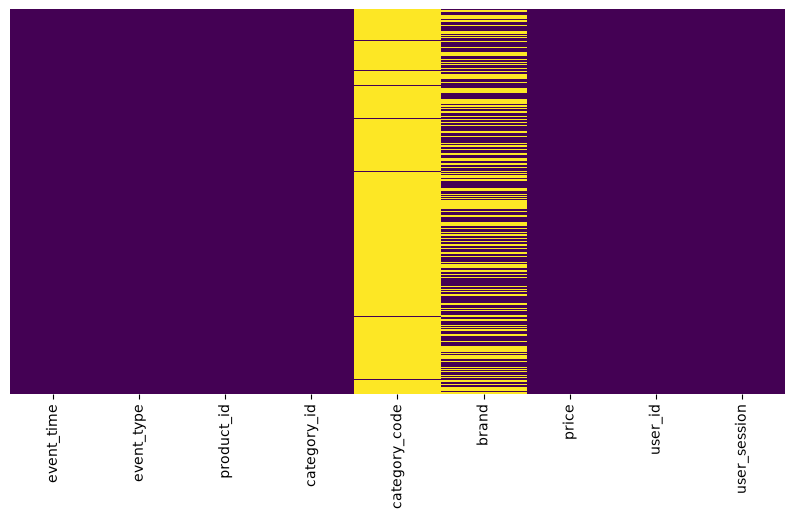

In [4]:
fig, ax = plt.subplots(figsize = (10,5))

sns_heatmap = sns.heatmap(df.sample(10000).isnull(),
                         yticklabels=False,
                         cbar = False,
                         cmap = 'viridis'
                         )

Посмотрим на описание колонок.

In [5]:
df.describe()

,product_id,category_id,price,user_id
count,4.635837e+06,4.635837e+06,4.635837e+06,4.635837e+06
mean,5.481406e+06,1.550049e+18,8.120701e+00,5.068070e+08
std,1.305582e+06,1.642371e+17,1.879197e+01,8.504375e+07
min,3.752000e+03,1.487580e+18,-7.937000e+01,1.120748e+06
25%,5.723529e+06,1.487580e+18,1.940000e+00,4.698573e+08
50%,5.810145e+06,1.487580e+18,3.970000e+00,5.421750e+08
75%,5.856186e+06,1.487580e+18,6.350000e+00,5.680491e+08
max,5.909246e+06,2.195085e+18,3.277800e+02,5.799699e+08


В таблице видно отрицательную цену -- очистим эти строки. Вероятно, они ошибочны

In [6]:
df = df[df['price']>=0]
df['price'].describe()

count    4.635820e+06
mean     8.120837e+00
std      1.879184e+01
min      0.000000e+00
25%      1.940000e+00
50%      3.970000e+00
75%      6.350000e+00
max      3.277800e+02
Name: price, dtype: float64

In [7]:
df.describe(include = 'object')

/tmp/ipykernel_11300/1466716981.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include = 'object')


,event_time,event_type,category_code,brand,user_session
count,4635820,4635820,75748,2649808,4635007
unique,1810735,4,10,239,942022
top,2019-11-18 01:17:08 UTC,view,appliances.environment.vacuum,runail,774a7c64-079f-450c-be4a-625aeea3350d
freq,279,2076132,32029,324850,2031


Разберемся со временем. Посмотрим в каком оно формате. Переведем в дни, часы, минуты и секунды. Дополнительно добавим колонку с днем недели. 0 -- понедельник, 6 -- воскресенье, отдельно выделим выходные. Это понадобится для когортного анализа.

In [8]:
df['event_time'].describe()

count                     4635820
unique                    1810735
top       2019-11-18 01:17:08 UTC
freq                          279
Name: event_time, dtype: object

In [9]:
df['event_time'].head()

0    2019-11-01 00:00:02 UTC
1    2019-11-01 00:00:09 UTC
2    2019-11-01 00:00:10 UTC
3    2019-11-01 00:00:11 UTC
4    2019-11-01 00:00:24 UTC
Name: event_time, dtype: str

In [10]:
df['event_time'] = pd.to_datetime(df['event_time'], format = 'mixed')

In [11]:
df['year'] = df['event_time'].dt.year
df['month'] = df['event_time'].dt.month
df['day'] = df['event_time'].dt.day
df['hour'] = df['event_time'].dt.hour
df['minute'] = df['event_time'].dt.minute
df['second'] = df['event_time'].dt.second
df['day_of_week'] = df['event_time'].dt.dayofweek

/tmp/ipykernel_11300/1869372842.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['day_of_week'] = df['event_time'].dt.dayofweek


In [12]:
df.head()

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,year,month,day,hour,minute,second,day_of_week
0,2019-11-01 00:00:02+00:00,view,5802432,1487580009286598681,NaN,NaN,0.32,562076640,09fafd6c-6c99-46b1-834f-33527f4de241,2019,11,1,0,0,2,4
1,2019-11-01 00:00:09+00:00,cart,5844397,1487580006317032337,NaN,NaN,2.38,553329724,2067216c-31b5-455d-a1cc-af0575a34ffb,2019,11,1,0,0,9,4
2,2019-11-01 00:00:10+00:00,view,5837166,1783999064103190764,NaN,pnb,22.22,556138645,57ed222e-a54a-4907-9944-5a875c2d7f4f,2019,11,1,0,0,10,4
3,2019-11-01 00:00:11+00:00,cart,5876812,1487580010100293687,NaN,jessnail,3.16,564506666,186c1951-8052-4b37-adce-dd9644b1d5f7,2019,11,1,0,0,11,4
4,2019-11-01 00:00:24+00:00,remove_from_cart,5826182,1487580007483048900,NaN,NaN,3.33,553329724,2067216c-31b5-455d-a1cc-af0575a34ffb,2019,11,1,0,0,24,4


# 2. Пользовательское поведение
#### проанализируем, как часто пользователи посещают сайт и возвращаются к нему.

#### 2.1 Посчитаем количество пользователей в день(DAU - метрика)

In [13]:
df_day = (
     df.groupby(['day','day_of_week'])
     .agg(DAU = ('user_id','nunique'))
     .sort_values('day')
    .reset_index()
 )
df_day.head()

,day,day_of_week,DAU
0,1,4,14880
1,2,5,14614
2,3,6,15530
3,4,0,16209
4,5,1,18545


Среднее число посетителей в день:18310.93
Серым на графике отмечены выходные


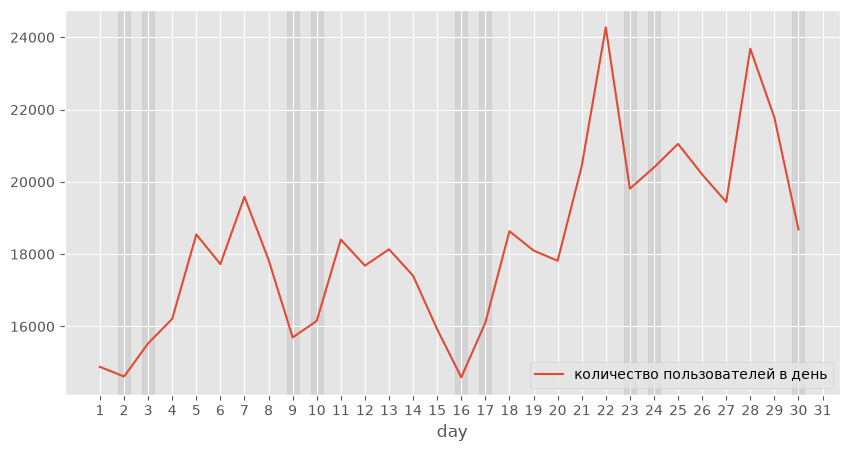

In [14]:
plt.style.use('ggplot')    
print(f"Среднее число посетителей в день:{df_day.DAU.mean().round(2)}")
print("Серым на графике отмечены выходные")
ax = df_day.plot(
    x='day',
    y='DAU',
    figsize = (10,5),
    xticks = range(1,32,1),
    label = 'количество пользователей в день'
)
for _, row in df_day[df_day['day_of_week'].isin([5, 6])].iterrows():
    ax.axvspan(row['day'] - 0.25, row['day'] + 0.25, color='black', alpha=0.075, zorder=0)
plt.show()


In [15]:
 df_day['DAU'].describe()

count       30.000000
mean     18310.933333
std       2473.990842
min      14591.000000
25%      16166.250000
50%      18117.000000
75%      19755.750000
max      24276.000000
Name: DAU, dtype: float64

**Вывод:** Основная волна посещений магазина приходится на четверг. В выходные происходит неожиданный спад активности. Видна недельная сезонность.

#### 2.2 Посчитаем активность пользователей в течение дня

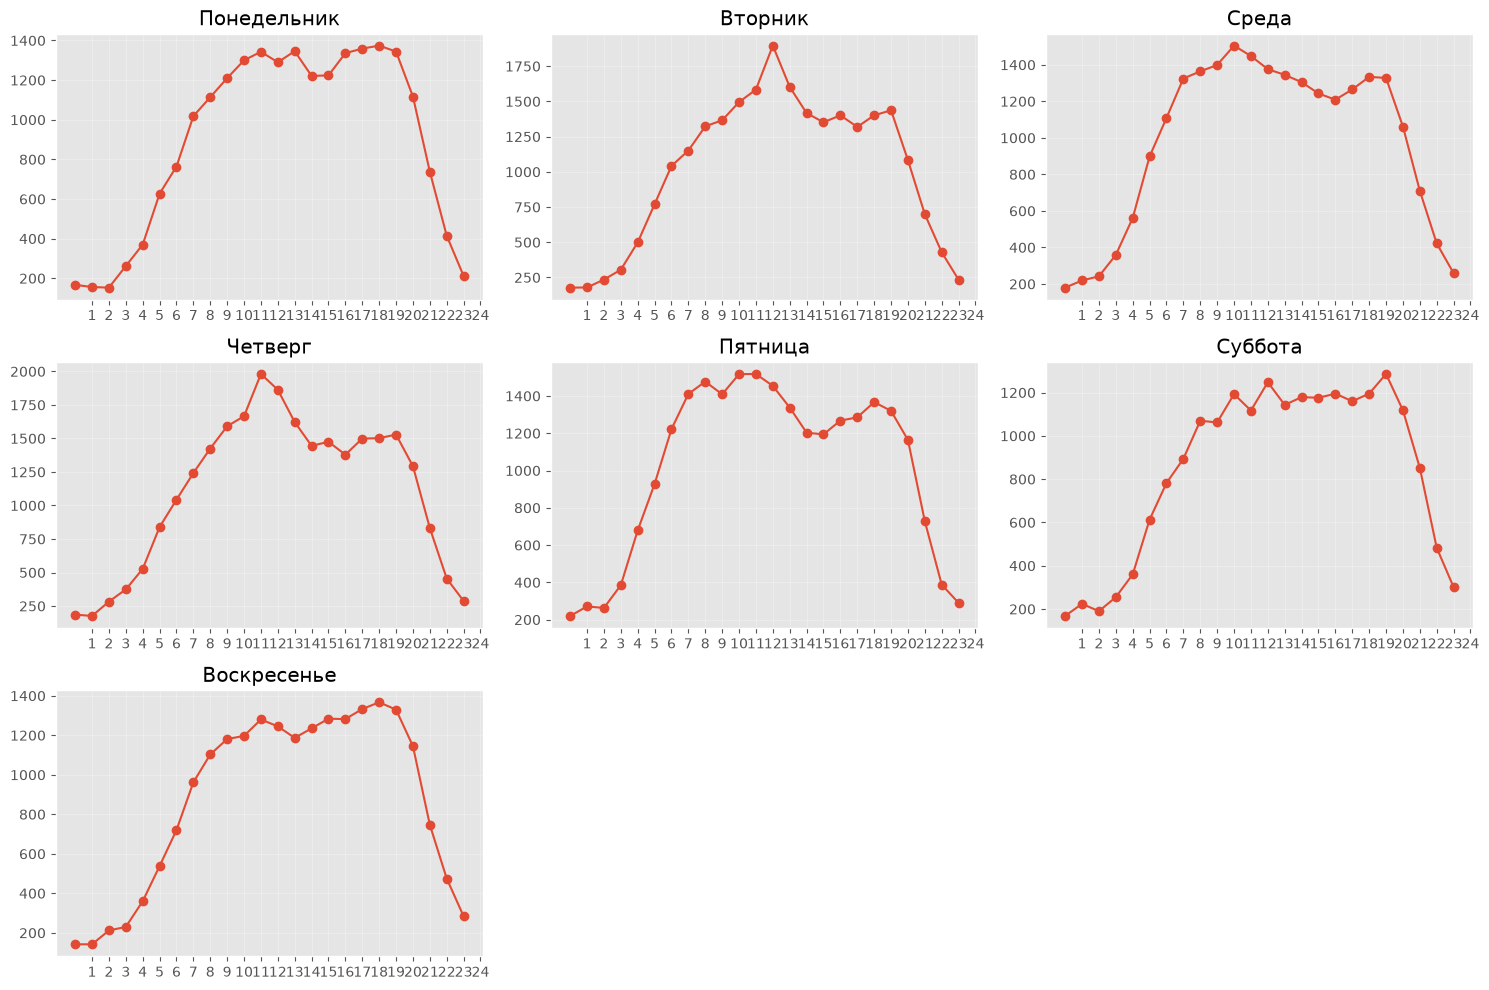

In [16]:
df_hour =(
    df.groupby(['day','hour'])
    .agg(hour_users = ('user_id','nunique'))
    .sort_values('day')
    .reset_index()
)

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()
days = ['Пятница', 'Суббота', 'Воскресенье',
        'Понедельник', 'Вторник', 'Среда', 'Четверг']

for i in range(4, 11):
    ax = axes[(i - 4)]
    d = df_hour[df_hour['day'] == i]
    ax.plot(d['hour'], d['hour_users'], marker='o') 
    ax.set_title(days[(i -1)%7])
    ax.set_xticks(range(1, 25))
    ax.grid(alpha=0.3)

axes[7].axis('off')
axes[8].axis('off')

fig.tight_layout()
plt.show()


Видно, что схожи: большой поток людей в середине дня, спад к ночи. Так же на некоторых дня есть выраженные горбы -- начало дня около 10 утра и конец дня около 20.

## 2.3 Как часто люди возвращаются?

Для ответа на такой вопрос проанализируем уникальных пользователей. Построим таблицу, которая покажет возврат пользователей на сайт.

берем день первого визита как когорту для каждого юзера. Каждому пользователю прикладываем эту информацию

In [17]:
first_session = df.groupby('user_id').agg(
    {'day':'min'}
).rename(columns={'day':'first_info_day'})

df_joined = df.merge(first_session, on = 'user_id',how='left') 

In [18]:
retention_abs = df_joined.pivot_table(
    index = 'first_info_day',
    columns = 'day',
    values = 'user_id',
    aggfunc = 'nunique'
)
retention_abs = retention_abs.sort_index(axis = 0).sort_index(axis = 1)
retention_abs

day,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
first_info_day,,,,,,,,,,,,,,,,,,,,,
1,14880.0,1784.0,1273.0,1173.0,1246.0,1099.0,1227.0,1018.0,802.0,750.0,...,882.0,947.0,677.0,687.0,697.0,676.0,690.0,808.0,803.0,591.0
2,NaN,12830.0,1308.0,866.0,728.0,634.0,698.0,596.0,517.0,512.0,...,490.0,551.0,464.0,450.0,389.0,383.0,347.0,466.0,408.0,373.0
3,NaN,NaN,12949.0,1326.0,825.0,655.0,657.0,572.0,517.0,501.0,...,439.0,483.0,408.0,400.0,348.0,331.0,373.0,420.0,404.0,339.0
4,NaN,NaN,NaN,12844.0,1190.0,676.0,654.0,517.0,417.0,461.0,...,384.0,404.0,335.0,372.0,325.0,314.0,271.0,358.0,335.0,270.0
5,NaN,NaN,NaN,NaN,14556.0,1261.0,925.0,689.0,414.0,423.0,...,437.0,592.0,361.0,338.0,447.0,355.0,357.0,479.0,422.0,262.0
6,NaN,NaN,NaN,NaN,NaN,13399.0,1141.0,684.0,406.0,411.0,...,349.0,409.0,296.0,272.0,302.0,283.0,321.0,356.0,297.0,214.0
7,NaN,NaN,NaN,NaN,NaN,NaN,14285.0,1232.0,566.0,487.0,...,434.0,587.0,338.0,322.0,345.0,322.0,325.0,445.0,351.0,242.0
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12537.0,797.0,473.0,...,329.0,421.0,262.0,278.0,247.0,258.0,254.0,291.0,274.0,195.0
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11259.0,847.0,...,241.0,267.0,266.0,245.0,228.0,219.0,197.0,249.0,212.0,199.0


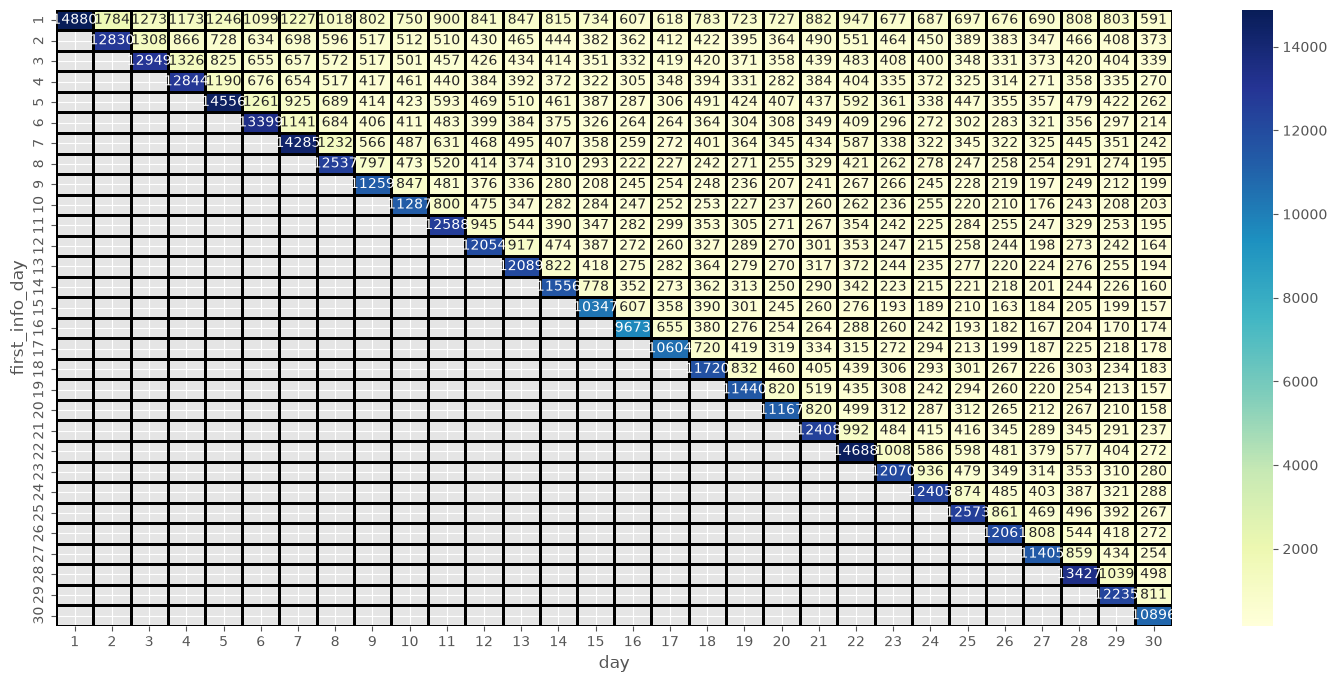

In [19]:
plt.figure(figsize = (18,8))

sns.heatmap(
    retention_abs,
    annot = True,
    fmt='.0f',
    linewidths=1, 
    linecolor='black', 
    cmap="YlGnBu"
    
);

Посчитаем в процентах, какая доля людей возвращается на сайт.

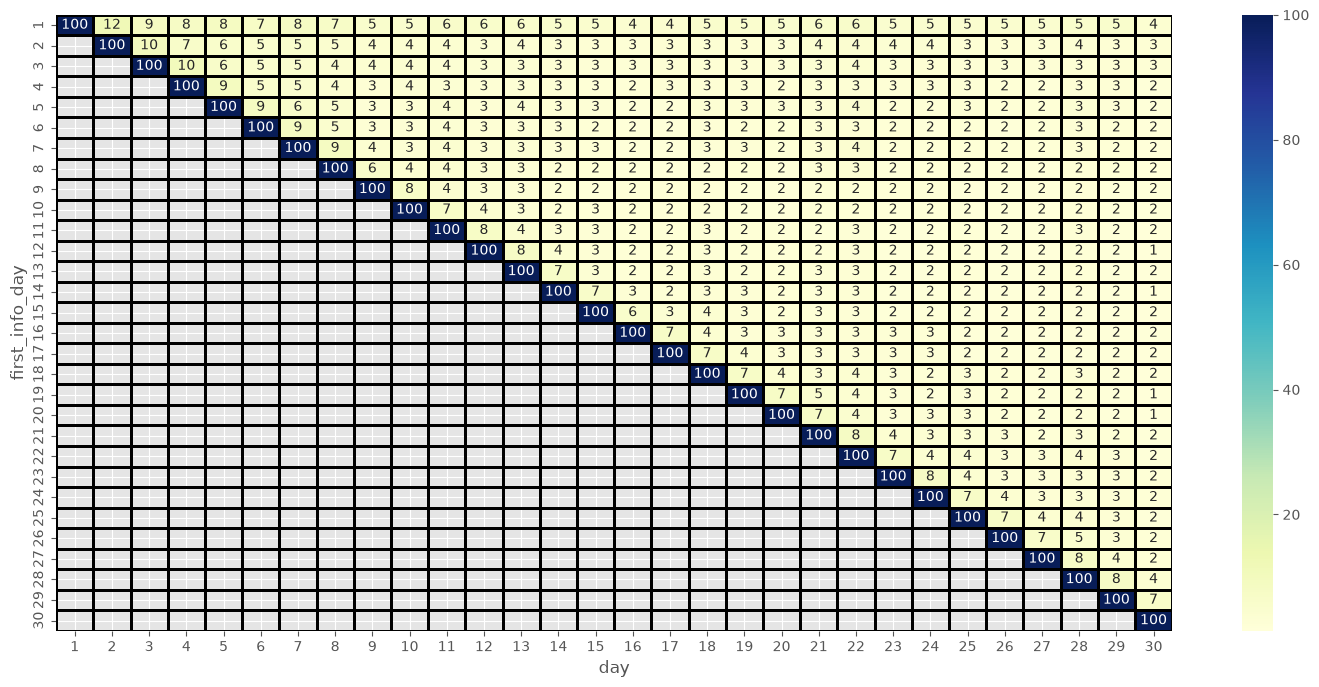

In [20]:
first_date = retention_abs.values.diagonal()
for diag, row in zip(first_date, retention_abs):
    retention_abs.loc[row] = 100*retention_abs.loc[row]/diag
    
plt.figure(figsize = (18,8))  

sns.heatmap(
    retention_abs,
    annot = True,
    fmt='.0f',
    linewidths=1, 
    linecolor='black', 
    cmap="YlGnBu"
    
);

Возвраты пользователей крайне малы. Где-то 8% возвращается на сайт на следующий день, а к концу месяца о сайте вспоминает лишь 1-2% пользователей.

Какая доля визитов относится ко дню, отличному от первого визита?

In [21]:
days_per_user = df.groupby('user_id')['day'].nunique()

returned_user = (days_per_user > 1).mean()
print(f'Доля пользователей, котоыре хотя бы 1 раз вернулись на сайт в другой день {returned_user.round(2)}')

Доля пользователей, котоыре хотя бы 1 раз вернулись на сайт в другой день 0.22


**Вывод:** пользователи редко возвращаются на сайт. Только каждый 5-й пользователь после первого открытия заходил на сайт в другой день недели.

## 3.Покупки
#### проведем анализ покупок, сделанных на сайте.

Расчитаем процент покупок

In [22]:
total_users = df['user_id'].nunique()
buyers = df[df['event_type'] == 'purchase']['user_id'].nunique()

revenue = 100 * buyers/total_users
print(f'Общее число покупателей: {buyers}')
print(f'Конверсия в покупку составляет {round(revenue,2)} %')


Общее число покупателей: 31524
Конверсия в покупку составляет 8.56 %


Оценим распределение выручки

In [23]:
df_buyers = df[df['event_type'] == 'purchase'].copy()
df_buyers = df_buyers.groupby('user_id').agg(
    total_sum = ('price','sum')
)
df_buyers.head()

,total_sum
user_id,
9794320,12.68
10079204,25.81
10280338,54.83
15781728,20.31
19762782,80.29


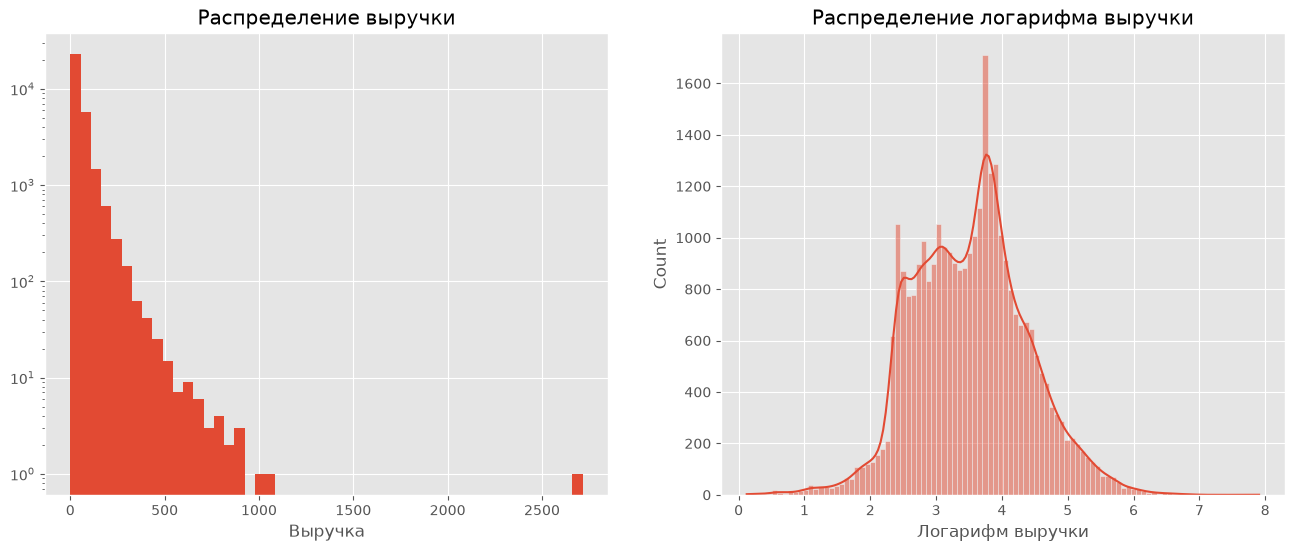

In [24]:
fig, ax = plt.subplots(1,2,figsize = (16,6))

df_buyers['total_sum'].hist(bins = 50, log = True, ax = ax[0])
sns.histplot(
    np.log(df_buyers['total_sum'] + 1),
    ax = ax[1],
    bins = 100,
    kde = True
)
ax[0].set_title("Распределение выручки")
ax[0].set_xlabel("Выручка")

ax[1].set_title("Распределение логарифма выручки")
ax[1].set_xlabel("Логарифм выручки")
plt.show()

Сколько времени в среднем проходит с момента первого просмотра до момента покупки?

In [25]:
df_buyers = df[df['event_type'] == 'purchase'].copy()
df_buyers = df_buyers.sort_values(by=['day', 'hour', 'second'])
first_day_buy = df_buyers.groupby('user_id').agg(
    
        first_day = ('day','min'),
        first_hour = ('hour','min'),
        first_sec = ('second','min'),
    )
first_day_buy.head()

,first_day,first_hour,first_sec
user_id,,,
9794320,25,5,13
10079204,6,10,30
10280338,20,11,9
15781728,16,23,59
19762782,10,19,1


In [26]:
df_buyers = df_buyers.join(first_day_buy, on = 'user_id')
df_buyers.head()

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,year,month,day,hour,minute,second,day_of_week,first_day,first_hour,first_sec
320,2019-11-01 00:25:26+00:00,purchase,5532,2195085258272014535,NaN,ingarden,3.65,566239468,3ad69360-e328-454a-b1f8-0e0901e1e344,2019,11,1,0,25,26,4,1,0,26
321,2019-11-01 00:25:26+00:00,purchase,5549786,1487580005595612013,NaN,NaN,3.00,566239468,3ad69360-e328-454a-b1f8-0e0901e1e344,2019,11,1,0,25,26,4,1,0,26
322,2019-11-01 00:25:26+00:00,purchase,5550302,2195085255034011676,NaN,NaN,1.21,566239468,3ad69360-e328-454a-b1f8-0e0901e1e344,2019,11,1,0,25,26,4,1,0,26
323,2019-11-01 00:25:26+00:00,purchase,5693001,1605161575889502297,NaN,lianail,4.75,566239468,3ad69360-e328-454a-b1f8-0e0901e1e344,2019,11,1,0,25,26,4,1,0,26
324,2019-11-01 00:25:26+00:00,purchase,5710313,1487580005092295511,NaN,lianail,5.54,566239468,3ad69360-e328-454a-b1f8-0e0901e1e344,2019,11,1,0,25,26,4,1,0,26


In [27]:
delta_last = 100*(df_buyers['day'] != df_buyers['first_day']).mean()
print(f"Доля покупок, совершаемых в последующие дни, после первой покупки {round(delta_last,2)}%")

Доля покупок, совершаемых в последующие дни, после первой покупки 14.08%


сколько дней проходит от первого захода на сайт до первой покупки?

In [28]:
views = df[df['event_type'] == 'view'].copy()

views = views.sort_values(by=['day', 'hour', 'second'])

first_view = views.drop_duplicates(subset='user_id', keep='first')

first_view = first_view[['user_id', 'day', 'hour', 'second']].rename(columns={
    'day': 'first_view_day',
    'hour': 'first_view_hour',
    'second': 'first_view_sec'
})

df_buyers = df_buyers.merge(first_view, on='user_id',how='left')
df_buyers['delta_days'] = df_buyers['day'] - df_buyers['first_view_day']
df_buyers['delta_days'].mean()

np.float64(5.5033335376139805)

In [29]:
print(f"В среднем покупка происходит после {df_buyers['delta_days'].mean().round(2)} дней на площадке")

В среднем покупка происходит после 5.5 дней на площадке


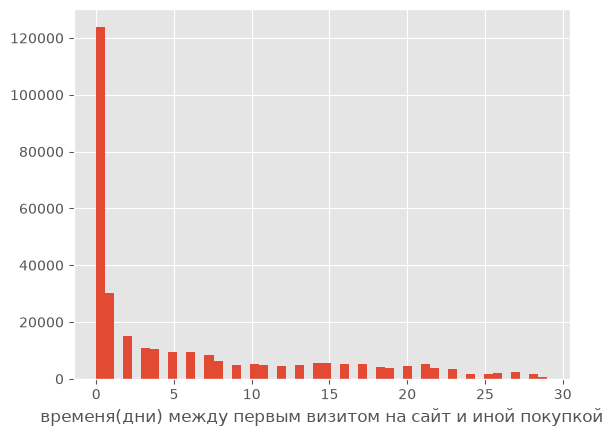

count    305806.000000
mean          5.695062
std           7.650943
min           0.000000
25%           0.000000
50%           1.000000
75%          10.000000
max          29.000000
Name: delta_days, dtype: float64

In [36]:
df_buyers = df_buyers[df_buyers['delta_days'] >= 0]
df_buyers['delta_days'].hist(bins = 50)
plt.xlabel("временя(дни) между первым визитом на сайт и иной покупкой")
plt.show()
df_buyers['delta_days'].describe()

In [42]:
df_buyers['delta_days'].quantile(0.8)



np.float64(13.0)

Посмотрим на динамику покупок

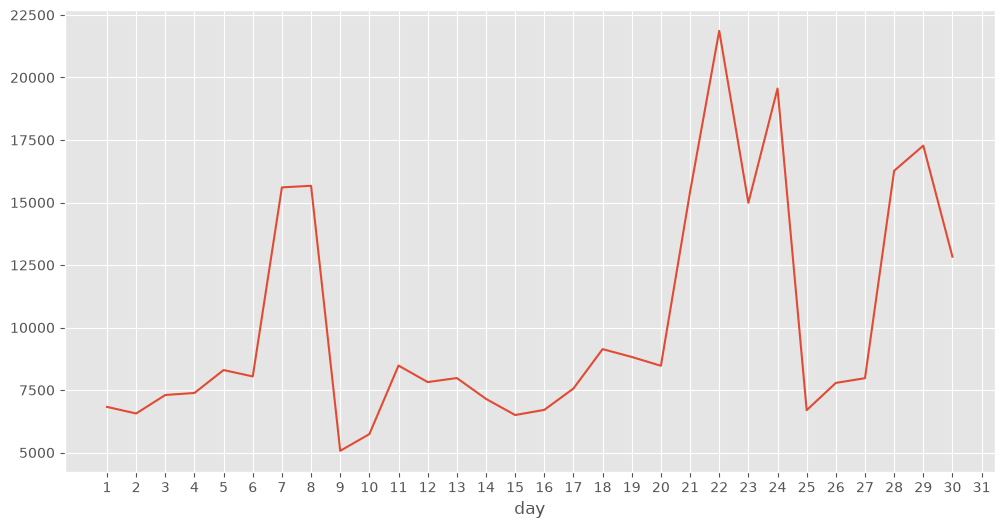

In [47]:
df_buyers.groupby('day')['user_id'].count().plot(
                                        figsize = (12,6),
                                        xticks = range(1,32)
                                        );

Видно, что график продаж сильно схож с графиком посещаемости сайта. Попробуем так же посмотреть на продажи по дням недеели и часам. Рассмотрим первую неделю 

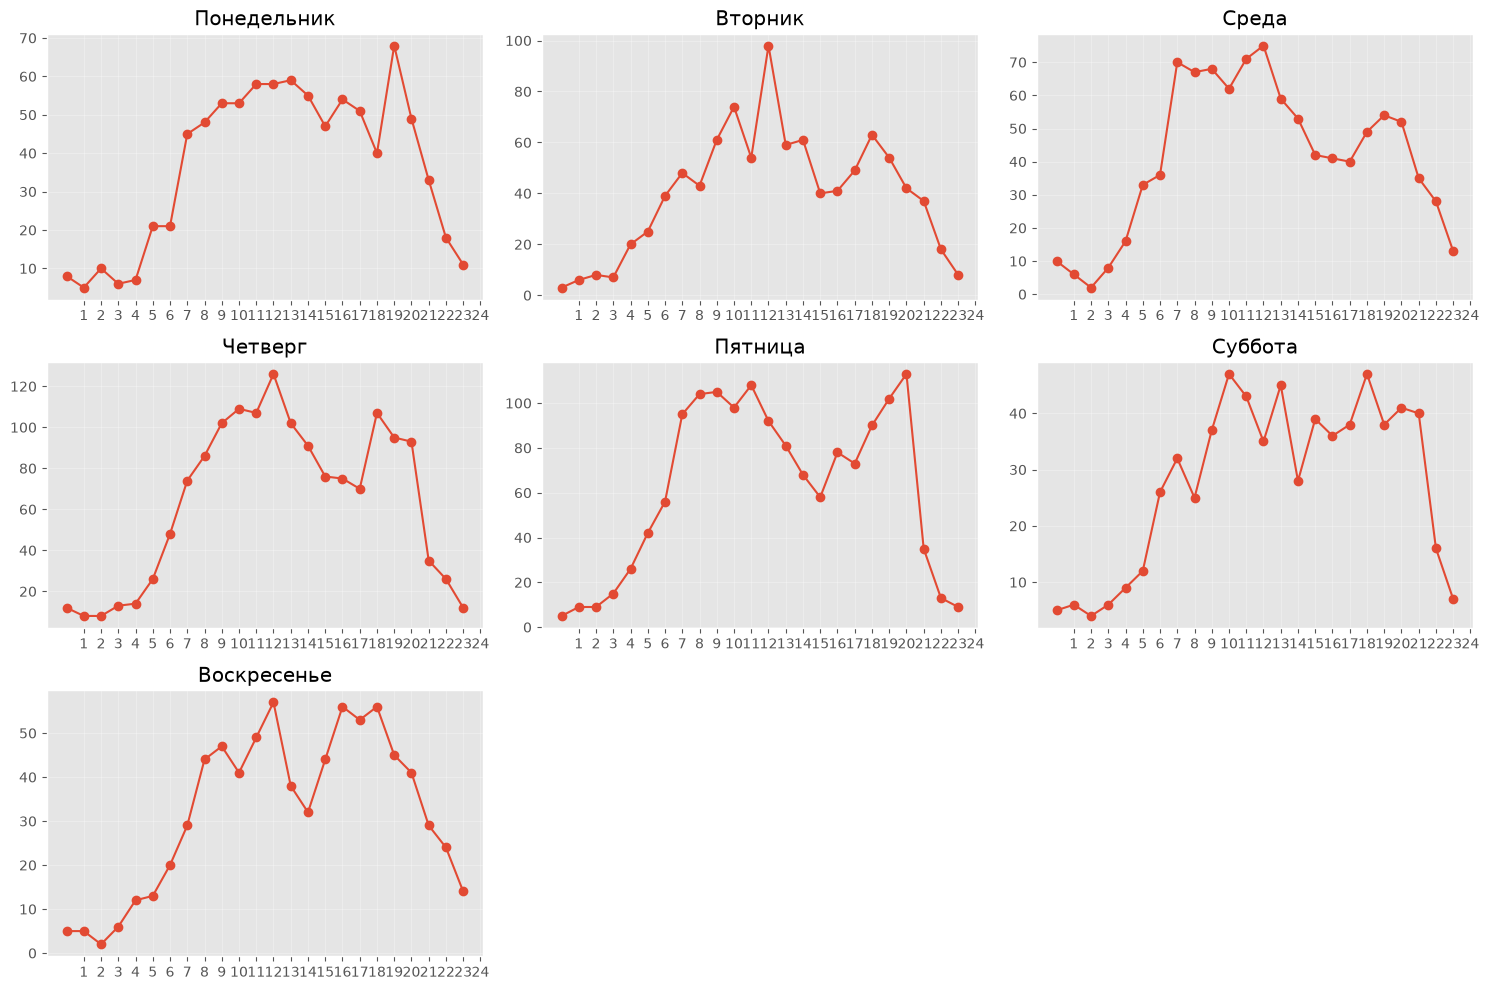

In [48]:
df_hour_buy =(
    df_buyers.groupby(['day','hour'])
    .agg(hour_users = ('user_id','nunique'))
    .sort_values('day')
    .reset_index()
)

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()
days = ['Пятница', 'Суббота', 'Воскресенье',
        'Понедельник', 'Вторник', 'Среда', 'Четверг']

for i in range(4, 11):
    ax = axes[(i - 4)]
    d = df_hour_buy[df_hour_buy['day'] == i]
    ax.plot(d['hour'], d['hour_users'], marker='o') 
    ax.set_title(days[(i -1)%7])
    ax.set_xticks(range(1, 25))
    ax.grid(alpha=0.3)

axes[7].axis('off')
axes[8].axis('off')

fig.tight_layout()
plt.show()

ярко выражены пики утром около 12 часов и вечером около 18.

## Воронка и основные метрики покупок
#### проведем подсчет ключевых показателей и построим воронку продаж

In [51]:
views = df[df['event_type'] == 'view']['user_id'].nunique()
cart = df[df['event_type'] == 'cart']['user_id'].nunique()
purchases = df[df['event_type'] == 'purchase']['user_id'].nunique()
funel_df = pd.DataFrame({
    'Этап':['1. Просмотр', '2. Корзина', '3. Покупка'],
    'Пользователи':[views, cart,purchases]
})

In [56]:

import plotly.express as px

fig = px.funnel(
    funel_df, 
    x='Пользователи', 
    y='Этап',
    title='Воронка продаж',
    color_discrete_sequence=['#1f77b4'] #Синий
)
fig.show(renderer="notebook") 

вычислим конверсии между шагами воронки продаж:

In [58]:
cr_view_cart = (cart / views) * 100
cr_cart_purchase = (purchases / cart) * 100
cr_total = (purchases / views) * 100

print(f"\nКонверсия View -> Cart: {cr_view_cart:.1f}%")
print(f"Конверсия Cart -> Purchase: {cr_cart_purchase:.1f}%")
print(f"Общая конверсия (CR): {cr_total:.2f}%")


Конверсия View -> Cart: 27.0%
Конверсия Cart -> Purchase: 32.9%
Общая конверсия (CR): 8.86%


Вычислим процент брошенных корзин: сколько людей добавили товар в корзину, но так его и не купили

In [60]:
users_with_cart = set(df[df['event_type'] == 'cart']['user_id'])
users_with_purchase = set(df[df['event_type'] == 'purchase']['user_id'])

abandoned = len(users_with_cart - users_with_purchase)
abandonment_rate = (abandoned / cart) * 100
print(f"Брошенные корзины: {abandonment_rate:.1f}%")

Брошенные корзины: 67.6%


Норма для e-commerce


Найдем средний чек покупки

In [65]:
avg_bill = df_buyers['price'].mean()
print(f'Средний чек покупки составляет {avg_bill:.1f}')

Средний чек покупки составляет 4.7


Рассчитаем процент повторных покупок

In [77]:
purchase_counts = df_buyers.groupby('user_id')['event_type'].count()
repeat_rate = (purchase_counts > 1).mean() * 100
print(f'доля людей, совершающие повторные покупки: {repeat_rate:.1f}%')

доля людей, совершающие повторные покупки: 91.7%


In [98]:
!pip install squarify

Построим карту покупок различных брендов

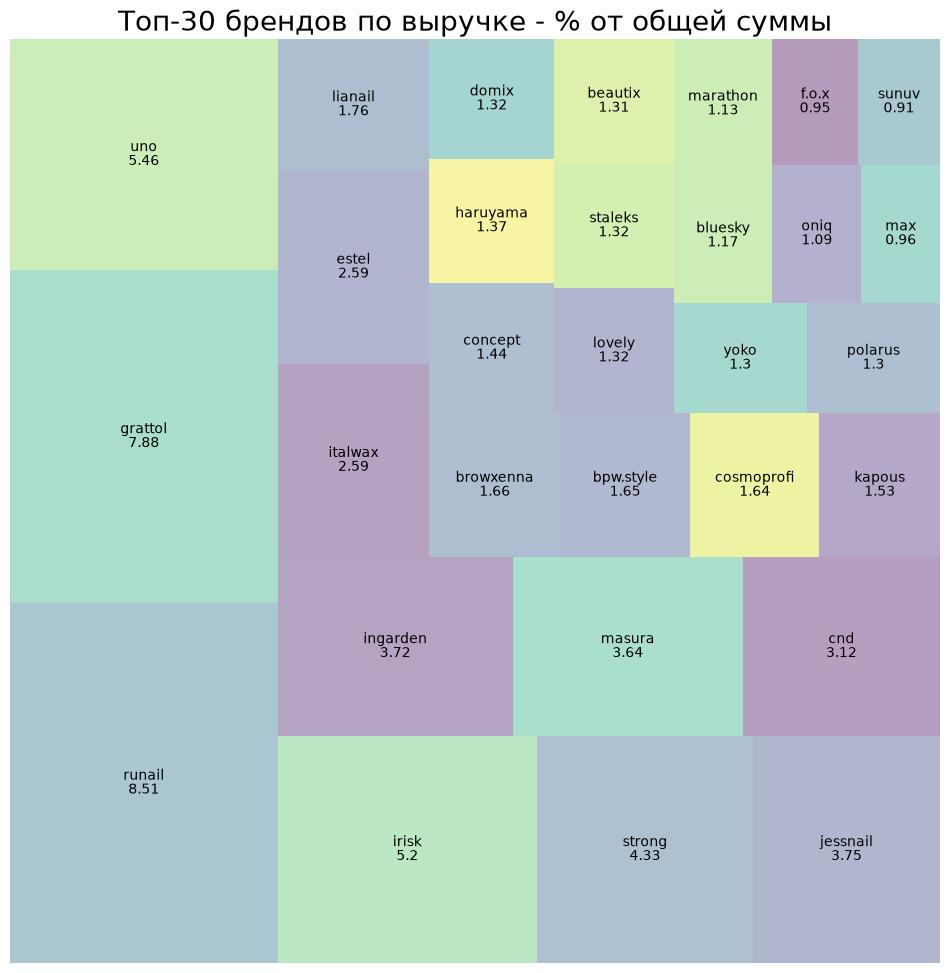

In [108]:
import squarify
brand_map = df_buyers.dropna(subset=['brand']).groupby('brand')['price'].sum()
total_brand = brand_map.sum()
brand_tree = round(brand_map.sort_values(ascending = False)[:30]/total_brand * 100,2)
plt.figure(figsize = (12,12))

g = squarify.plot(
    sizes=brand_tree.values, 
    label=brand_tree.index, 
    value=brand_tree.values,
    alpha=.4
)

g.set_title("Топ-30 брендов по выручке - % от общей суммы", fontsize=20)
g.set_axis_off();

## Основные выводы
**1. Трафик и активность:**
*   **DAU:** В среднем 18 310 пользователей в день.
*   **Сезонность:** Пик активности — четверг. В выходные (особенно в субботу) — аномальный спад трафика.
*   **Часы:** Два пика активности — около 12:00 и 18:00, ночью — сильный спад.

**2. Возвращаемость (Retention):**
*   **Крайне низкая.** На следующий день возвращается ~8%, к концу месяца — 1-2%. 
*   Только **22%** пользователей заходят на сайт более чем в один день.

**3. Конверсия и покупки:**
*   **CR (Conversion Rate):** 8.56% уникальных посетителей совершают покупку.
*   **Время до покупки:** В среднем 5.5 дней. Медиана — 1 день. 80% покупок совершаются в первые 13 дней.
*   **Повторные покупки:** 14% покупок совершаются в дни, отличные от первой покупки.
*   **Сумма чека:** Логнормальное распределение (преобладают небольшие чеки, есть редкие крупные).

**4. Воронка продаж:**
*   Наибольший отвал происходит на этапе между просмотром и добавлением в корзину. Динамика продаж полностью повторяет динамику трафика.

**5. Качество данных:**
*   Критический уровень пропусков в колонках `category_code` (98%) и `brand` (43%).